# IND320 - Project 3: Data to Decision

## Part 3 – Weather data, outliers, anomalies and time-series decomposition

### Shapefiles from NVE Atlas

Two shapefiles were downloaded from atlas.nve.no and stored in the `shapefiles/` folder:

- **Budområder** (`shapefiles/elspot/`): the five electricity price areas NO1–NO5.
- **NVE_Region** (`shapefiles/regions/`): the five NVE regions (RØ, RS, RV, RM, RN), used as
  precipitation areas. As noted in the assignment, East corresponds to RS+RØ and North to RM+RN.

Both files use the projected ETRS89 / UTM zone 33N coordinate system (metres), so they are
converted to longitude/latitude (WGS84), which is the format required by the Open-Meteo API.

,area,geometry
0,NO1,"POLYGON ((11.80905 62.8288, 11.81389 62.8274, ..."
1,NO2,"POLYGON ((5.74061 60.3517, 5.74081 60.35085, 5..."
2,NO3,"POLYGON ((10.87378 65.41986, 10.98433 65.40083..."
3,NO4,"POLYGON ((28.33596 71.29423, 28.36301 71.29201..."
4,NO5,"POLYGON ((7.41477 61.85483, 7.41637 61.85293, ..."


,REGION,REGIONNAVN,geometry
0,RV,Region Vest,"POLYGON ((9.06206 62.37261, 9.03652 62.36454, ..."
1,RM,Region Midt-Norge,"POLYGON ((12.54589 66.59724, 12.57049 66.58119..."
2,RN,Region Nord,"POLYGON ((31.10426 69.97927, 30.88899 69.84112..."
3,RØ,Region Øst,"POLYGON ((10.56069 60.16556, 10.55883 60.16561..."
4,RS,Region Sør,"POLYGON ((10.56069 60.16556, 10.56435 60.1611,..."


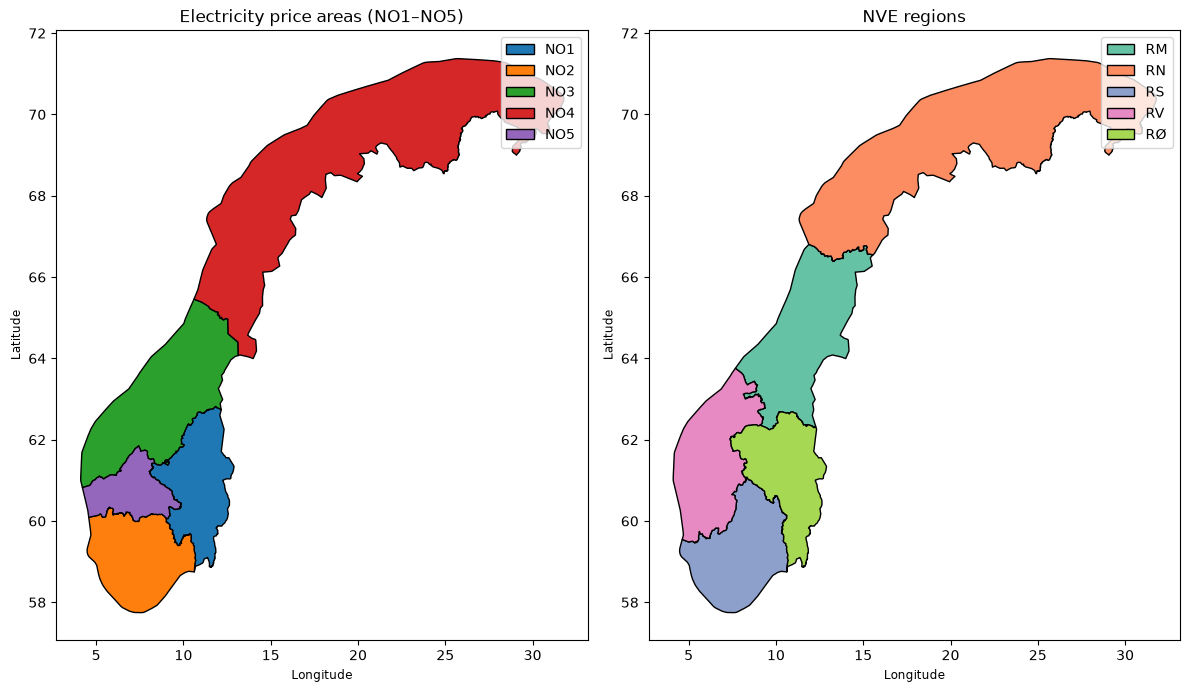

In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

SHAPE_DIR = Path("../shapefiles")

def load_shapefile(folder):
    """Load the single .shp file in a folder and convert it to longitude/latitude (WGS84)."""
    shp_file = next(Path(folder).glob("*.shp"))       # avoids typing names with special letters (å, ø)
    gdf = gpd.read_file(shp_file, encoding="utf-8")   # attribute text (e.g. 'Region Øst') is UTF-8
    return gdf.to_crs(epsg=4326)                      # UTM 33N (metres) -> WGS84 (degrees)

# Electricity price areas NO1-NO5
elspot = load_shapefile(SHAPE_DIR / "elspot")
elspot["area"] = elspot["budomr"].str.replace(" ", "")   # 'NO 1' -> 'NO1'

# NVE regions (precipitation areas)
regions = load_shapefile(SHAPE_DIR / "regions")

display(elspot[["area", "geometry"]])
display(regions[["REGION", "REGIONNAVN", "geometry"]])

# Quick visual check of both maps
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
elspot.plot(column="area", ax=axes[0], legend=True, edgecolor="black", cmap="tab10")
axes[0].set_title("Electricity price areas (NO1–NO5)")
regions.plot(column="REGION", ax=axes[1], legend=True, edgecolor="black", cmap="Set2")
axes[1].set_title("NVE regions")
for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()